## 1. Imports & Setup

Імпортуємо необхідні бібліотеки та налаштовуємо середовище для навчання й оцінювання RetinaNet.

In [ ]:

import json
from pathlib import Path

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_ROOT = Path(
    "/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026"
)

print("Device:", DEVICE)
print("Available inputs:", [p.name for p in Path("/kaggle/input").iterdir()])


Device: cuda
Available inputs: ['notebooks', 'competitions']


In [ ]:
%pip install -q pycocotools

Note: you may need to restart the kernel to use updated packages.


## 2. Load Preprocessed Annotations
Завантажуємо підготовлені annotations і спільне розбиття на 3 folds. Усі кадри однієї відеопослідовності належать до одного fold, щоб уникнути витоку даних.

Для зменшення часу навчання використовуємо кожен 6-й кадр для train і кожен 2-й для validation.

In [ ]:
PREPROCESSED_ROOT = Path(
    "/kaggle/input/notebooks/alinabodnarpn/02-preprocessing/preprocessed"
)

assert (PREPROCESSED_ROOT / "train.json").is_file()
assert (PREPROCESSED_ROOT / "folds.json").is_file()

with open(PREPROCESSED_ROOT / "train.json") as f:
    train_data = json.load(f)

with open(PREPROCESSED_ROOT / "folds.json") as f:
    fold_assignments = json.load(f)

assert len(train_data) == 24201
assert len(fold_assignments) == len(train_data)
assert set(fold_assignments) == {
    str(rec["file_name"]) for rec in train_data
}

assert set(fold_assignments.values()) == {0, 1, 2}

print("Fold assignments verified")

print("Training records:", len(train_data))
print("Folds:", set(fold_assignments.values()))
print("Preprocessing:", PREPROCESSED_ROOT)


Fold assignments verified
Training records: 24201
Folds: {0, 1, 2}
Preprocessing: /kaggle/input/notebooks/alinabodnarpn/02-preprocessing/preprocessed


In [ ]:
import random
import re
from collections import defaultdict
import numpy as np

SEED = 42
FOLD = 2

N_SPLITS = 3
TRAIN_FRAME_STEP = 6
VAL_FRAME_STEP = 2

EPOCHS = 6
BATCH_SIZE = 2
LR = 1e-4

assert FOLD in range(N_SPLITS)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


def sequence_name(rec):
    return Path(
        str(rec["file_name"]).replace("\\", "/")
    ).parent.name


def frame_sort_key(rec):
    name = Path(rec["file_name"]).stem
    match = re.search(r"(\d+)$", name)

    return (
        int(match.group(1)) if match else float("inf"),
        name
    )


def sample_by_sequence(records, step):
    grouped = defaultdict(list)

    for rec in records:
        grouped[sequence_name(rec)].append(rec)

    selected = []

    for sequence in sorted(grouped):
        frames = sorted(
            grouped[sequence],
            key=frame_sort_key
        )
        selected.extend(frames[::step])

    return selected


full_fold_train = [
    rec for rec in train_data
    if fold_assignments[rec["file_name"]] != FOLD
]

full_fold_val = [
    rec for rec in train_data
    if fold_assignments[rec["file_name"]] == FOLD
]

fold_train_data = sample_by_sequence(
    full_fold_train, TRAIN_FRAME_STEP
)

fold_val_data = sample_by_sequence(
    full_fold_val, VAL_FRAME_STEP
)

train_sequences = set(map(sequence_name, fold_train_data))
val_sequences = set(map(sequence_name, fold_val_data))

assert train_sequences.isdisjoint(val_sequences)
assert fold_train_data and fold_val_data

print(f"Fold {FOLD}")
print(f"Train: {len(full_fold_train)} -> {len(fold_train_data)}")
print(f"Validation: {len(full_fold_val)} -> {len(fold_val_data)}")
print("Train sequences:", len(train_sequences))
print("Val sequences:", len(val_sequences))


Fold 2
Train: 16162 -> 2713
Validation: 8039 -> 4024
Train sequences: 38
Val sequences: 18


## 3. Dataset & DataLoader

Створюємо Dataset для завантаження зображень та bounding boxes. Для train застосовуємо випадкове горизонтальне віддзеркалення, а для validation — лише необхідні перетворення.

In [ ]:

import numpy as np
from PIL import Image
from torchvision import tv_tensors
from torchvision.transforms import v2 as T

class DetectionDataset(Dataset):
    def __init__(self, records, split, train=False):
        self.records = records
        self.split = split
        self.transforms = T.Compose(
            ([T.RandomHorizontalFlip(p=0.5)] if train else []) +
            [T.ToDtype(torch.float32, scale=True), T.ToPureTensor()]
        )

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        path = DATA_ROOT / self.split / rec["file_name"]

        with Image.open(path) as img:
            image = np.array(img.convert("RGB"), copy=True)

        h, w = image.shape[:2]
        image = tv_tensors.Image(torch.from_numpy(image).permute(2, 0, 1))

        target = {
            "boxes": tv_tensors.BoundingBoxes(
                torch.tensor(rec["boxes"], dtype=torch.float32).reshape(-1, 4),
                format="XYXY", canvas_size=(h, w)
            ),
            "labels": torch.tensor(rec["labels"], dtype=torch.int64),
            "ignored_boxes": tv_tensors.BoundingBoxes(
                torch.tensor(rec["ignored_boxes"], dtype=torch.float32).reshape(-1, 4),
                format="XYXY", canvas_size=(h, w)
            )
        }

        return self.transforms(image, target)

def collate_fn(batch):
    return tuple(zip(*batch))


train_dataset = DetectionDataset(
    fold_train_data,
    split="train",
    train=True
)

val_dataset = DetectionDataset(
    fold_val_data,
    split="train",
    train=False
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))


Training images: 2713
Validation images: 4024


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=True
)

## 4. RetinaNet Baseline

Використовуємо RetinaNet із pretrained ResNet-50 та FPN. Адаптуємо classification head до 8 класів датасету.

Залишаємо стандартні anchors і Focal Loss. Окремо враховуємо ignored regions, щоб модель не отримувала штраф за нерозмічені об'єкти в цих областях.

In [ ]:

from torchvision.models.detection import (
    retinanet_resnet50_fpn,
    RetinaNet_ResNet50_FPN_Weights
)
from torchvision.models.detection.retinanet import RetinaNetClassificationHead

NUM_CLASSES = 9

model = retinanet_resnet50_fpn(
    weights=RetinaNet_ResNet50_FPN_Weights.DEFAULT
)

num_anchors = model.anchor_generator.num_anchors_per_location()[0]

model.head.classification_head = RetinaNetClassificationHead(
    model.backbone.out_channels,
    num_anchors,
    NUM_CLASSES
)

model = model.to(DEVICE)


Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_coco-eeacb38b.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_coco-eeacb38b.pth


100%|██████████| 130M/130M [00:00<00:00, 210MB/s]  


## 5. Baseline Training

Навчаємо RetinaNet на Fold 2 протягом 6 епох із batch size 2 та learning rate 1e-4.

Під час обчислення classification loss ігноруємо негативні anchors, що потрапляють в ignored regions. Після кожної епохи зберігаємо checkpoint.

In [ ]:

from torchvision.models.detection.transform import resize_boxes

original_resize = model.transform.resize

def resize_with_ignore(image, target):
    old_size = image.shape[-2:]
    image, target = original_resize(image, target)

    if target is not None and "ignored_boxes" in target:
        target["ignored_boxes"] = resize_boxes(
            target["ignored_boxes"], old_size, image.shape[-2:]
        )

    return image, target

model.transform.resize = resize_with_ignore


In [ ]:

from types import MethodType
from torchvision.ops import box_iou
from torchvision.models.detection import _utils as det_utils

def compute_loss_with_ignore(self, targets, head_outputs, anchors):
    matched_idxs = []

    for anchor, target in zip(anchors, targets):
        boxes = target["boxes"]

        if len(boxes):
            matches = self.proposal_matcher(box_iou(boxes, anchor))
        else:
            matches = torch.full(
                (len(anchor),), -1, dtype=torch.long, device=anchor.device
            )

        ignored = target.get("ignored_boxes")
        if ignored is not None and len(ignored):
            centers = (anchor[:, :2] + anchor[:, 2:]) / 2
            ignore_mask = torch.zeros(len(anchor), dtype=torch.bool, device=anchor.device)

            for box in ignored.unique(dim=0):
                ignore_mask |= (
                    (centers[:, 0] >= box[0]) &
                    (centers[:, 0] <= box[2]) &
                    (centers[:, 1] >= box[1]) &
                    (centers[:, 1] <= box[3])
                )

            matches[(matches < 0) & ignore_mask] = det_utils.Matcher.BETWEEN_THRESHOLDS

        matched_idxs.append(matches)

    return self.head.compute_loss(targets, head_outputs, anchors, matched_idxs)

model.compute_loss = MethodType(compute_loss_with_ignore, model)


In [ ]:
from tqdm.auto import tqdm

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=DEVICE.type == "cuda"
)

OUTPUT_DIR = Path(
    f"/kaggle/working/retinanet/fold_{FOLD}"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = OUTPUT_DIR / "fold_latest.pth"

In [ ]:

train_losses = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0

    for images, targets in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
        images = [img.to(DEVICE) for img in images]
        targets = [
            {k: v.to(DEVICE) for k, v in t.items()}
            for t in targets
        ]

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast("cuda", enabled=DEVICE.type == "cuda"):
            losses = model(images, targets)
            loss = sum(losses.values())
            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite loss at epoch {epoch + 1}"
                )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * len(images)

    epoch_loss = total_loss / len(train_dataset)
    train_losses.append(epoch_loss)

    payload = {
    "fold": FOLD,
    "epoch": epoch + 1,
    "model": model.state_dict(),
    "optimizer": optimizer.state_dict(),
    "scaler": scaler.state_dict(),
    "train_losses": train_losses,
    "train_frame_step": TRAIN_FRAME_STEP,
    "val_frame_step": VAL_FRAME_STEP,
    "epochs": EPOCHS,
    "lr": LR,
    }

    temp_path = checkpoint_path.with_suffix(".tmp")
    torch.save(payload, temp_path)
    temp_path.replace(checkpoint_path)
    print(f"Epoch {epoch+1}: Loss = {epoch_loss:.4f}")


Epoch 1/6:   0%|          | 0/1357 [00:00<?, ?it/s]

Epoch 1: Loss = 0.6898


Epoch 2/6:   0%|          | 0/1357 [00:00<?, ?it/s]

Epoch 2: Loss = 0.5143


Epoch 3/6:   0%|          | 0/1357 [00:00<?, ?it/s]

Epoch 3: Loss = 0.9229


... (2 outputs left out)

Epoch 5/6:   0%|          | 0/1357 [00:00<?, ?it/s]

Epoch 5: Loss = 0.5571


Epoch 6/6:   0%|          | 0/1357 [00:00<?, ?it/s]

Epoch 6: Loss = 1.0038


## 6. Baseline Evaluation

Оцінюємо навчену модель на validation-даних за метриками mAP, AP50, AP75 та AP для об'єктів різного розміру.

Також вимірюємо швидкість inference. Для коректного оцінювання ignored regions враховуємо під час COCO evaluation.

In [ ]:
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["fold"] == FOLD

model.load_state_dict(checkpoint["model"])
model.to(DEVICE)
model.eval()

print("Loaded fold:", checkpoint["fold"])
print("Loaded epoch:", checkpoint["epoch"])
print("Training losses:", checkpoint["train_losses"])

Loaded fold: 2
Loaded epoch: 6
Training losses: [0.6897641569101367, 0.5143160165300942, 0.922856339417917, 0.9468245079738822, 0.5570517617576113, 1.0037665195540664]


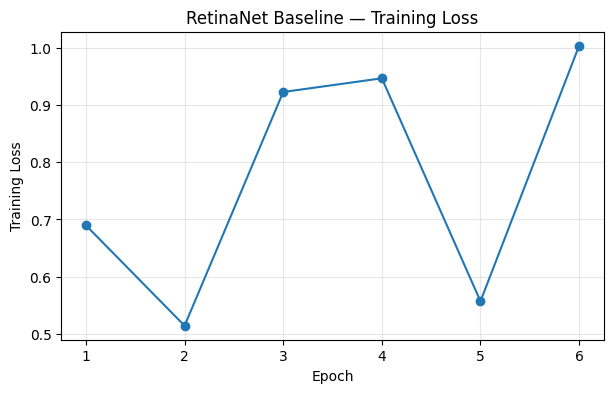

In [ ]:

import matplotlib.pyplot as plt

train_losses = checkpoint["train_losses"]

plt.figure(figsize=(7, 4))
plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("RetinaNet Baseline — Training Loss")
plt.xticks(range(1, len(train_losses) + 1))
plt.grid(alpha=0.3)
plt.show()


In [ ]:

import time
import json
import numpy as np

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from tqdm.auto import tqdm


CLASS_NAMES = {
    1: "person",
    2: "bicycle",
    3: "car",
    4: "van",
    5: "truck",
    6: "tricycle",
    7: "bus",
    8: "motor"
}


def xyxy_to_xywh(box):
    x1, y1, x2, y2 = [float(v) for v in box]
    return [
        x1, y1,
        max(0.0, x2 - x1),
        max(0.0, y2 - y1)
    ]


def build_coco_gt(records):
    images = []
    annotations = []
    annotation_id = 1

    for rec in records:
        image_id = int(rec["image_id"])

        images.append({
            "id": image_id,
            "file_name": rec["file_name"]
        })

        for box, label in zip(rec["boxes"], rec["labels"]):
            bbox = xyxy_to_xywh(box)

            if bbox[2] <= 0 or bbox[3] <= 0:
                continue

            annotations.append({
                "id": annotation_id,
                "image_id": image_id,
                "category_id": int(label),
                "bbox": bbox,
                "area": bbox[2] * bbox[3],
                "iscrowd": 0
            })
            annotation_id += 1

        for box in rec["ignored_boxes"]:
            bbox = xyxy_to_xywh(box)

            if bbox[2] <= 0 or bbox[3] <= 0:
                continue

            for label in CLASS_NAMES:
                annotations.append({
                    "id": annotation_id,
                    "image_id": image_id,
                    "category_id": label,
                    "bbox": bbox,
                    "area": bbox[2] * bbox[3],
                    "iscrowd": 1
                })
                annotation_id += 1

    coco = COCO()
    coco.dataset = {
        "images": images,
        "annotations": annotations,
        "categories": [
            {"id": i, "name": name}
            for i, name in CLASS_NAMES.items()
        ],
        "info": {},
        "licenses": []
    }
    coco.createIndex()

    return coco


In [ ]:

def evaluate_retinanet(model, data_loader, records):
    model.eval()

    predictions = []
    inference_times = []

    assert len(records) == len(data_loader.dataset)

    record_index = 0

    with torch.inference_mode():
        for images, _ in tqdm(data_loader, desc="Validation"):
            images_gpu = [
                image.to(DEVICE, non_blocking=True)
                for image in images
            ]

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            start = time.perf_counter()
            outputs = model(images_gpu)

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            elapsed = time.perf_counter() - start
            inference_times.append(elapsed / len(images))

            for output in outputs:
                rec = records[record_index]
                image_id = int(rec["image_id"])
                record_index += 1

                boxes = output["boxes"].cpu().tolist()
                labels = output["labels"].cpu().tolist()
                scores = output["scores"].cpu().tolist()

                for box, label, score in zip(boxes, labels, scores):
                    if int(label) not in CLASS_NAMES:
                        continue

                    bbox = xyxy_to_xywh(box)

                    if bbox[2] <= 0 or bbox[3] <= 0:
                        continue

                    predictions.append({
                        "image_id": image_id,
                        "category_id": int(label),
                        "bbox": bbox,
                        "score": float(score)
                    })

    assert record_index == len(records)

    coco_gt = build_coco_gt(records)

    if predictions:
        coco_dt = coco_gt.loadRes(predictions)

        evaluator = COCOeval(coco_gt, coco_dt, iouType="bbox")
        evaluator.params.imgIds = [
            int(r["image_id"]) for r in records
        ]
        evaluator.params.catIds = list(CLASS_NAMES)
        evaluator.params.maxDets = [1, 10, 100]

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

        stats = [float(v) for v in evaluator.stats]
    else:
        stats = [0.0] * 12

    mean_time = float(np.mean(inference_times))

    metrics = {
        "mAP": stats[0],
        "AP50": stats[1],
        "AP75": stats[2],
        "AP_small": stats[3],
        "AP_medium": stats[4],
        "AP_large": stats[5],
        "inference_ms_per_image": mean_time * 1000,
        "FPS_equivalent_batch1": (
            1.0 / mean_time if mean_time > 0 else 0.0
        ),
        "images_evaluated": len(records),
        "num_predictions": len(predictions)
    }

    return metrics, predictions


fold_metrics, fold_predictions = evaluate_retinanet(
    model,
    val_loader,
    fold_val_data
)

(OUTPUT_DIR / "metrics_quick.json").write_text(
    json.dumps(fold_metrics, indent=2)
)

(OUTPUT_DIR / "predictions_quick.json").write_text(
    json.dumps(fold_predictions)
)

(OUTPUT_DIR / "config.json").write_text(
    json.dumps({
        "fold": FOLD,
        "epochs": EPOCHS,
        "train_frame_step": TRAIN_FRAME_STEP,
        "val_frame_step": VAL_FRAME_STEP,
        "batch_size": BATCH_SIZE,
        "lr": LR,
        "seed": SEED,
        "validation_images": len(fold_val_data),
        "evaluation_note": (
            "COCO-style evaluation with category-specific "
            "crowd annotations for ignored regions"
        )
    }, indent=2)
)

print("Fold:", FOLD)
print(json.dumps(fold_metrics, indent=2))
print("Results saved to:", OUTPUT_DIR)


Validation:   0%|          | 0/4024 [00:00<?, ?it/s]

creating index...
index created!
Loading and preparing results...
DONE (t=1.76s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=346.53s).
Accumulating evaluation results...
DONE (t=7.39s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.058
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.130
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.045
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.021
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.074
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.114
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.029
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.114
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.151
 Average Recall     (AR) @[ IoU=0

In [ ]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

FOLD = 2

fold_dir = Path(f"/kaggle/working/retinanet/fold_{FOLD}")
zip_path = Path(f"/kaggle/working/retinanet_fold_{FOLD}_results.zip")

required = [
    "fold_latest.pth",
    "metrics_quick.json",
    "predictions_quick.json",
    "config.json"
]

for name in required:
    assert (fold_dir / name).is_file(), f"Missing file: {name}"

with ZipFile(zip_path, "w", ZIP_DEFLATED) as z:
    for file in fold_dir.iterdir():
        if file.is_file():
            z.write(file, arcname=f"fold_{FOLD}/{file.name}")

print("Saved:", zip_path)
print("Size:", round(zip_path.stat().st_size / 1024**2, 2), "MB")

with ZipFile(zip_path) as z:
    print("Files inside ZIP:")
    for name in z.namelist():
        print(" ", name)


Saved: /kaggle/working/retinanet_fold_2_results.zip
Size: 350.89 MB
Files inside ZIP:
  fold_2/predictions_quick.json
  fold_2/metrics_quick.json
  fold_2/config.json
  fold_2/fold_latest.pth


## 7. RetinaNet — 3-Fold Baseline Analysis

Порівнюємо якість RetinaNet на всіх трьох validation folds. Це дозволяє оцінити, наскільки результати моделі залежать від конкретного розбиття даних.

In [ ]:
import json
import pandas as pd
from pathlib import Path

FOLD_DIRS = {
    0: Path("/kaggle/input/notebooks/alinabodnarpn/04-retinanet-fold0/retinanet/fold_0"),
    1: Path("/kaggle/input/datasets/alinabodnarpn/retinanet-fold-1/fold_1"),
    2: Path("/kaggle/input/notebooks/alinabodnarpn/04-retinanet-fold2/retinanet/fold_2"),
}

rows = []

for fold, folder in FOLD_DIRS.items():
    with open(folder / "metrics_quick.json") as f:
        metrics = json.load(f)

    rows.append({
        "Fold": fold,
        "mAP": metrics["mAP"],
        "AP50": metrics["AP50"],
        "AP75": metrics["AP75"],
        "AP_small": metrics["AP_small"],
        "AP_medium": metrics["AP_medium"],
        "AP_large": metrics["AP_large"],
        "Inference (ms)": metrics["inference_ms_per_image"],
        "Images": metrics["images_evaluated"],
    })

df = pd.DataFrame(rows).sort_values("Fold")

display(df.round(4))

,Fold,mAP,AP50,AP75,AP_small,AP_medium,AP_large,Inference (ms),Images
0,0,0.1818,0.3556,0.1672,0.0537,0.1381,0.2837,198.7974,4044
1,1,0.1277,0.2491,0.1164,0.0221,0.1321,0.2760,195.9490,4046
2,2,0.0576,0.1302,0.0445,0.0209,0.0744,0.1136,202.4765,4024


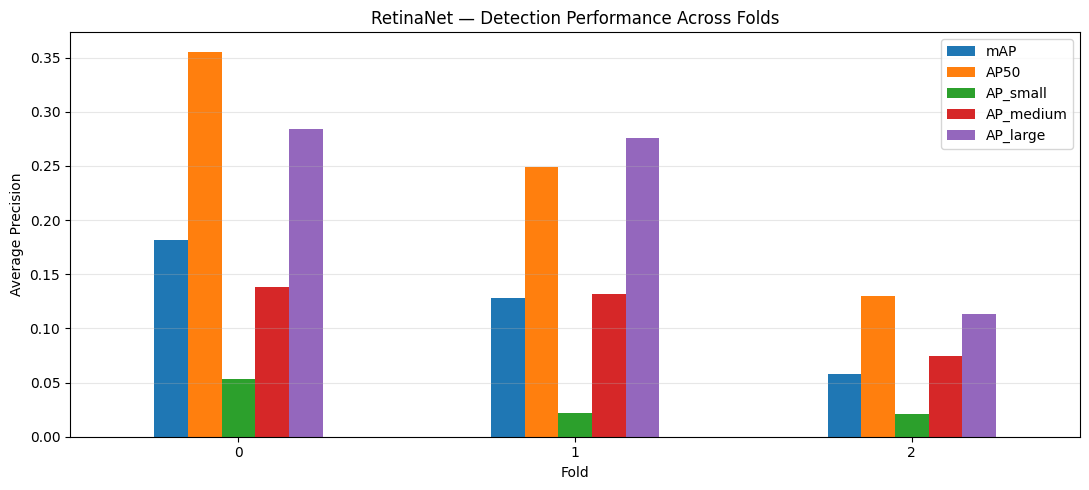

In [ ]:

import matplotlib.pyplot as plt

metrics_to_plot = [
    "mAP",
    "AP50",
    "AP_small",
    "AP_medium",
    "AP_large",
]

ax = df.set_index("Fold")[metrics_to_plot].plot(
    kind="bar",
    figsize=(11, 5)
)

ax.set_title("RetinaNet — Detection Performance Across Folds")
ax.set_ylabel("Average Precision")
ax.set_xlabel("Fold")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


Fold 0: epochs=6, final loss=0.3070
Fold 1: epochs=6, final loss=0.3886
Fold 2: epochs=6, final loss=1.0038


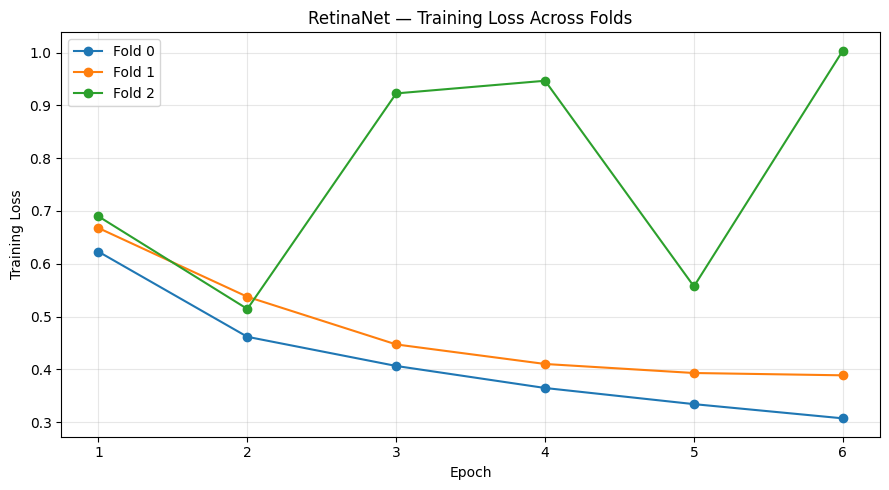

In [ ]:

import torch
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for fold, folder in FOLD_DIRS.items():
    checkpoint = torch.load(
        folder / "fold_latest.pth",
        map_location="cpu",
        weights_only=False
    )

    losses = checkpoint["train_losses"]

    plt.plot(
        range(1, len(losses) + 1),
        losses,
        marker="o",
        label=f"Fold {fold}"
    )

    print(
        f"Fold {fold}: "
        f"epochs={checkpoint['epoch']}, "
        f"final loss={losses[-1]:.4f}"
    )

    del checkpoint

plt.title("RetinaNet — Training Loss Across Folds")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Висновок

Результати RetinaNet помітно відрізняються між folds. Найкращий mAP отримано на Fold 0 (0.1818), тоді як на Fold 1 він становить 0.1277, а на Fold 2 — лише 0.0576.

Також на Fold 2 спостерігається нестабільний training loss, який наприкінці навчання залишається значно вищим, ніж на інших folds. Це може свідчити про складніше розбиття даних або нестабільність навчання.

Отже, оцінювання лише на одному fold було б недостатньо надійним. Для подальшого порівняння моделей використовуватимемо результати всіх трьох folds.

## 8. Порівняння tuning на трьох folds

Об'єднуємо результати baseline та двох експериментів: зменшення learning rate до 5e-5 і зміни Focal Loss alpha до 0.5.

Порівнюємо середні метрики за трьома folds, щоб визначити, які налаштування покращують якість детекції та наскільки стабільними є результати.

In [1]:

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/AI_HW2")
IMPORTS = ROOT / "kaggle_imports"

assert ROOT.is_dir(), f"Folder not found: {ROOT}"
assert IMPORTS.is_dir(), f"Folder not found: {IMPORTS}"

print("Kaggle archives:")
for p in sorted(IMPORTS.glob("*.zip")):
    print(" -", p.name)


Mounted at /content/drive
Kaggle archives:
 - retinanet_fold0_tuning_results.zip
 - retinanet_fold_0_results.zip
 - retinanet_fold_2_results (1).zip


In [3]:

import json
import pandas as pd
from zipfile import ZipFile
from pathlib import Path

METRICS = [
    "mAP", "AP50", "AP75",
    "AP_small", "AP_medium", "AP_large"
]

def find_archive(pattern):
    matches = list(IMPORTS.glob(pattern))
    assert len(matches) == 1, (
        f"Expected one archive for {pattern}, found: {matches}"
    )
    return matches[0]


BASELINE_F0_ZIP = find_archive("*fold_0_results.zip")
BASELINE_F2_ZIP = find_archive("*fold_2_results*.zip")
TUNING_F0_ZIP = find_archive("*fold0_tuning*.zip")


def read_drive_metrics(folder):
    path = folder / "metrics_quick.json"
    assert path.is_file(), f"Missing: {path}"
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def read_zip_metrics(zip_path, fold, experiment=None):
    with ZipFile(zip_path) as z:
        candidates = [
            name for name in z.namelist()
            if name.endswith(f"fold_{fold}/metrics_quick.json")
        ]

        if experiment is not None:
            candidates = [
                name for name in candidates
                if experiment in Path(name).parts
            ]

        assert len(candidates) == 1, (
            f"Cannot identify {experiment} fold_{fold} in "
            f"{zip_path.name}: {candidates}"
        )

        with z.open(candidates[0]) as f:
            return json.load(f)


records = []

for fold in range(3):
    for experiment in [
        "Baseline",
        "Exp 1 — LR 5e-5",
        "Exp 2 — alpha 0.5"
    ]:
        if experiment == "Baseline":
            if fold == 0:
                data = read_zip_metrics(BASELINE_F0_ZIP, 0)
            elif fold == 1:
                data = read_drive_metrics(
                    ROOT / "retinanet" / "fold_1"
                )
            else:
                data = read_zip_metrics(BASELINE_F2_ZIP, 2)

        elif experiment == "Exp 1 — LR 5e-5":
            if fold == 0:
                data = read_zip_metrics(
                    TUNING_F0_ZIP, 0, "lr_5e-5"
                )
            else:
                data = read_drive_metrics(
                    ROOT / "retinanet_tuning"
                    / "lr_5e-5" / f"fold_{fold}"
                )

        else:
            if fold == 0:
                data = read_zip_metrics(
                    TUNING_F0_ZIP, 0, "focal_alpha_05"
                )
            else:
                data = read_drive_metrics(
                    ROOT / "retinanet_tuning"
                    / "focal_alpha_05" / f"fold_{fold}"
                )

        row = {"Fold": fold, "Experiment": experiment}
        row.update({key: data[key] for key in METRICS})
        records.append(row)

results = pd.DataFrame(records)

assert len(results) == 9

display(results.round(4))


,Fold,Experiment,mAP,AP50,AP75,AP_small,AP_medium,AP_large
0,0,Baseline,0.1818,0.3556,0.1672,0.0537,0.1381,0.2837
1,0,Exp 1 — LR 5e-5,0.1871,0.3704,0.1707,0.0520,0.1537,0.3099
2,0,Exp 2 — alpha 0.5,0.1822,0.3568,0.1656,0.0531,0.1396,0.2890
3,1,Baseline,0.1277,0.2491,0.1164,0.0221,0.1321,0.2760
4,1,Exp 1 — LR 5e-5,0.1409,0.2705,0.1321,0.0237,0.1437,0.3203
5,1,Exp 2 — alpha 0.5,0.0101,0.0248,0.0074,0.0029,0.0111,0.0170
6,2,Baseline,0.0576,0.1302,0.0445,0.0209,0.0744,0.1136
7,2,Exp 1 — LR 5e-5,0.1370,0.2733,0.1248,0.0395,0.1357,0.3431
8,2,Exp 2 — alpha 0.5,0.1046,0.2256,0.0866,0.0374,0.1155,0.2416


In [4]:

ORDER = [
    "Baseline",
    "Exp 1 — LR 5e-5",
    "Exp 2 — alpha 0.5"
]

means = (
    results.groupby("Experiment")[METRICS]
    .mean()
    .reindex(ORDER)
)

stds = (
    results.groupby("Experiment")[METRICS]
    .std()
    .reindex(ORDER)
)

summary = means.copy()

summary.insert(1, "mAP_std", stds["mAP"])

baseline_map = means.loc["Baseline", "mAP"]

summary["ΔmAP"] = summary["mAP"] - baseline_map
summary["ΔmAP (%)"] = (
    (summary["mAP"] / baseline_map - 1) * 100
)

display(summary.round(4))


,mAP,mAP_std,AP50,AP75,AP_small,AP_medium,AP_large,ΔmAP,ΔmAP (%)
Experiment,,,,,,,,,
Baseline,0.1224,0.0623,0.2450,0.1094,0.0322,0.1149,0.2245,0.0000,0.0000
Exp 1 — LR 5e-5,0.1550,0.0279,0.3047,0.1425,0.0384,0.1444,0.3244,0.0326,26.6665
Exp 2 — alpha 0.5,0.0990,0.0861,0.2024,0.0865,0.0312,0.0887,0.1826,-0.0234,-19.1358


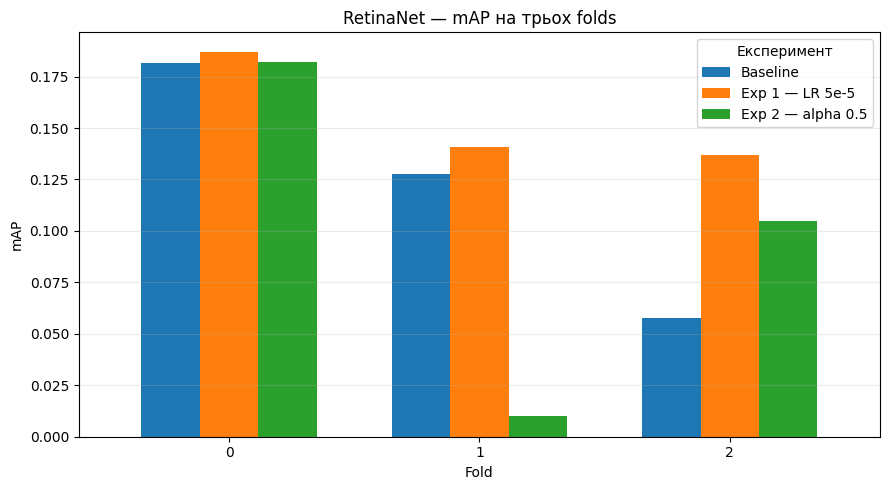

In [5]:

import matplotlib.pyplot as plt

pivot = (
    results.pivot(
        index="Fold",
        columns="Experiment",
        values="mAP"
    )
    .reindex(columns=ORDER)
)

ax = pivot.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7,
    rot=0
)

ax.set_title("RetinaNet — mAP на трьох folds")
ax.set_xlabel("Fold")
ax.set_ylabel("mAP")
ax.legend(title="Експеримент")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


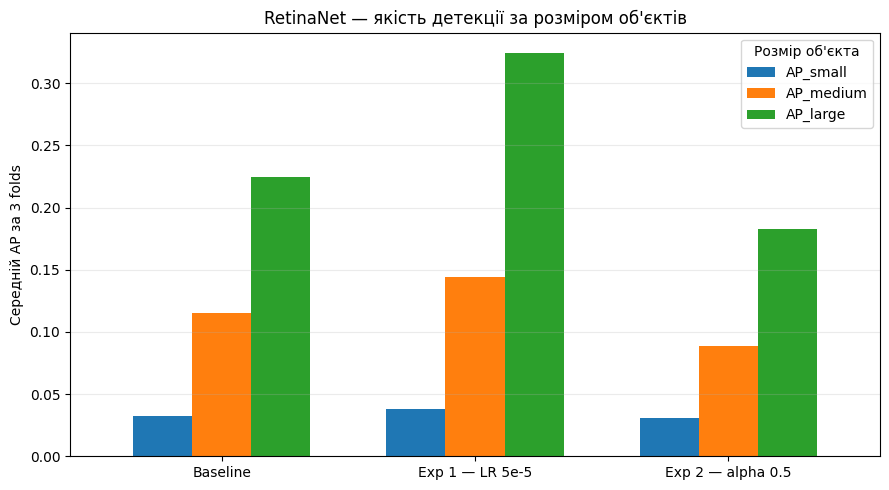

In [6]:

size_metrics = [
    "AP_small",
    "AP_medium",
    "AP_large"
]

size_means = means[size_metrics]

ax = size_means.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0,
    width=0.7
)

ax.set_title(
    "RetinaNet — якість детекції за розміром об'єктів"
)
ax.set_xlabel("")
ax.set_ylabel("Середній AP за 3 folds")
ax.legend(title="Розмір об'єкта")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


In [7]:

baseline = (
    results[results["Experiment"] == "Baseline"]
    .set_index("Fold")["mAP"]
)

comparison = (
    pivot.subtract(baseline, axis=0)
    .drop(columns="Baseline")
)

print("Зміна mAP відносно baseline:")
display(comparison.round(4))

print("\nКількість folds із покращенням:")
print((comparison > 0).sum().to_string())

ANALYSIS_DIR = ROOT / "retinanet_analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

results.to_csv(
    ANALYSIS_DIR / "all_fold_metrics.csv",
    index=False
)

summary.to_csv(
    ANALYSIS_DIR / "tuning_summary.csv"
)

print("\nТаблиці збережено в:", ANALYSIS_DIR)


Зміна mAP відносно baseline:


Experiment,Exp 1 — LR 5e-5,Exp 2 — alpha 0.5
Fold,,
0,0.0053,0.0003
1,0.0132,-0.1175
2,0.0794,0.0469



Кількість folds із покращенням:
Experiment
Exp 1 — LR 5e-5      3
Exp 2 — alpha 0.5    2

Таблиці збережено в: /content/drive/MyDrive/AI_HW2/retinanet_analysis


## 9. Висновок по RetinaNet

Ми порівняли baseline RetinaNet та два tuning-експерименти за допомогою 3-fold cross-validation.

**Найкращі результати отримано після зменшення learning rate з 1e-4 до 5e-5.** Середній mAP зріс із 0.1224 до 0.1550 (+26.7%), а стандартне відхилення між folds зменшилося з 0.0623 до 0.0279. Покращення спостерігається на всіх трьох folds, що свідчить про стабільнішу якість моделі.

**Модифікація Focal Loss (alpha = 0.5)** не дала стабільного покращення. На Fold 0 та Fold 2 результати трохи зросли, але на Fold 1 mAP сильно знизився до 0.0101. Тому середній mAP цього експерименту виявився нижчим за baseline — 0.0990.

Окремою проблемою залишається детекція малих об'єктів: навіть у найкращого експерименту AP_small становить лише 0.0384, тоді як AP_large — 0.3244.

**Отже, для подальшого порівняння з іншими детекторами обираємо RetinaNet із learning rate = 5e-5.** Його результати є найкращими та найстабільнішими серед протестованих налаштувань.